# Visualisation Tools for ECG Signals

In this notebook, I developed a series of tools for visualising ECG signals. 

#### Functions
**plot_signal(signal_number)**: Plots a single signal in full. 

**plot_signal_with_peaks(signal_number, cutoff)**: Plots a single signal with peaks above the cutoff label. 

**plot_signal_with_troughs(signal_number, cutoff)**: Plots a single signal with troughs in magnitude larger than the cutoff labeled. 

**plot_segment(signal_number, t1, t2)**: Plot a segment of a single signal ranging from t1 to t2. 

### Using WFDB to Read Signal Data
The documentation for WFDB is available here: https://wfdb.readthedocs.io/en/latest/

In [12]:
import wfdb
from wfdb import processing
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

#### Plotting each Signal in a Directory
Press enter to create the plot of each sequential signal in the directory.  

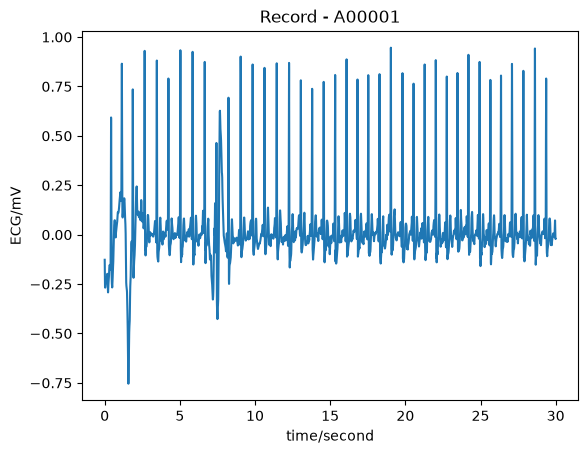

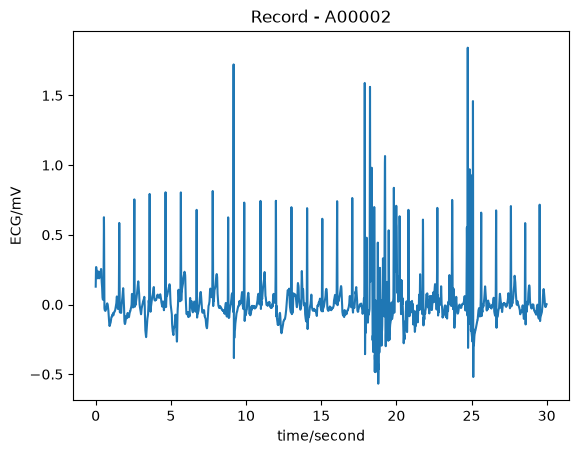

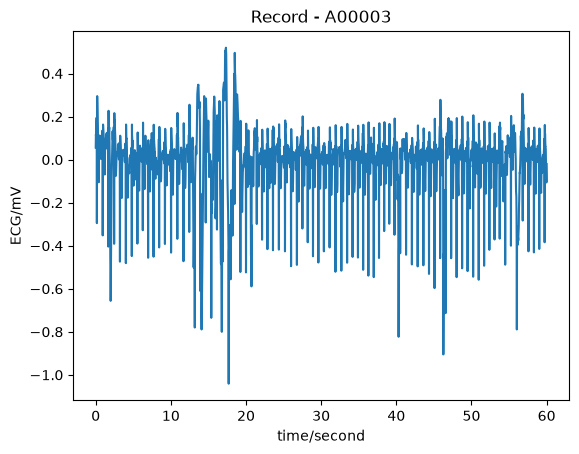

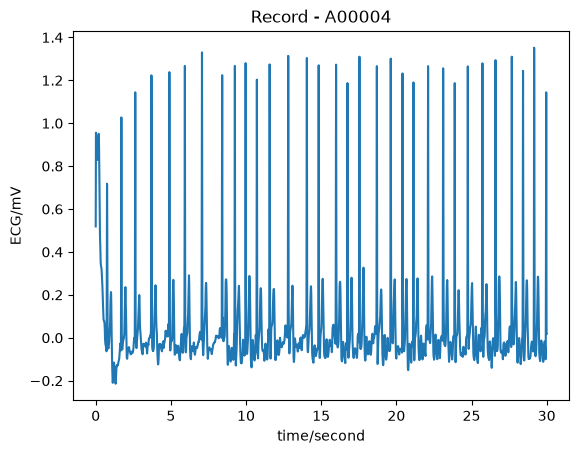

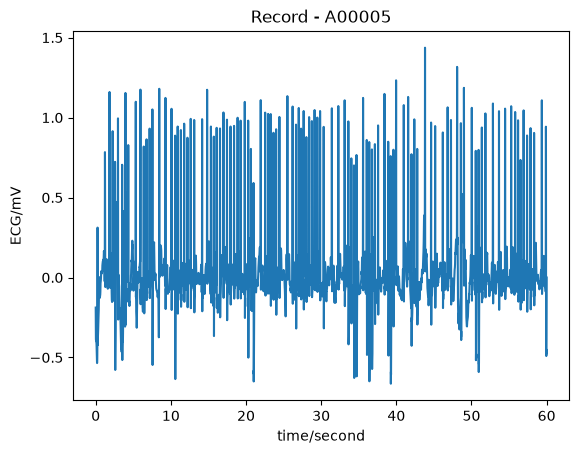

KeyboardInterrupt: Interrupted by user

In [3]:
wfdb.plot.plot_all_records('physionet2017/training2017')

#### Plotting an Individual Signal

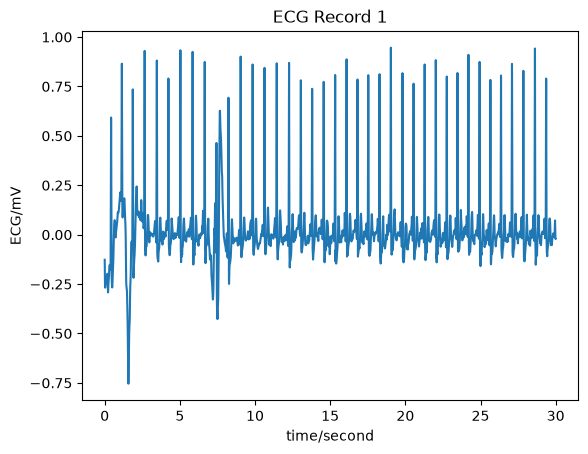

In [4]:
def plot_signal(signal_number):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}')

    wfdb.plot_wfdb(record=record,  
                   title=f'ECG Record {signal_number}', 
                   time_units='seconds')

plot_signal(1)

#### Annotating an ECG Plot - Peaks

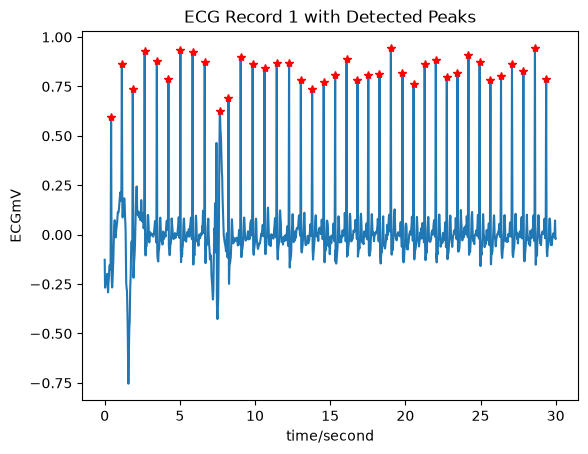

In [6]:
def plot_signal_with_peaks(signal_number, cutoff):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}') 

    peaks, _ = find_peaks(record.p_signal[:, 0], height=cutoff, distance=100)

    ann = wfdb.Annotation(record_name=f'physionet2017/training2017/A{signal_number:05d}',
                      extension='', # Annotation of the sample
                      sample=peaks, # Peak is a np array containing the annotation locations
                      symbol=['N'] * len(peaks), # Symbols used to display annotation labels
                      chan=np.zeros(len(peaks), dtype=int), # A np array containing the signal channel for each annotation
                      fs=record.fs) # Sampling frequency

    wfdb.plot_wfdb(record=record, annotation=ann, title=f'ECG Record {signal_number} with Detected Peaks', time_units='seconds')

plot_signal_with_peaks(1, cutoff=0.5)

#### Annotating an ECG Plot - Troughs

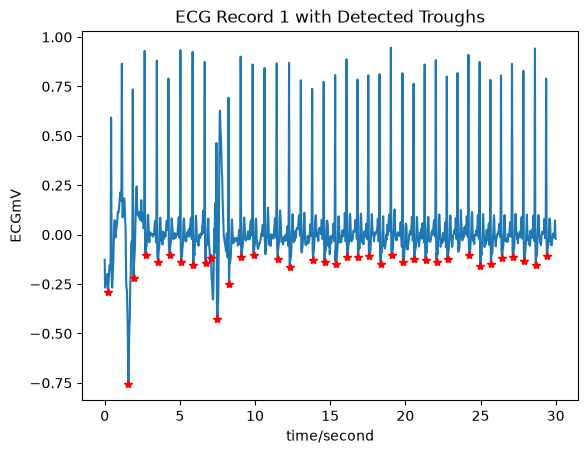

In [7]:
def plot_signal_with_troughs(signal_number, cutoff):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}') # Read the record

    troughs, _ = find_peaks(-record.p_signal[:, 0], height=cutoff, distance=100)

    ann = wfdb.Annotation(record_name=f'physionet2017/training2017/A{signal_number:05d}',
                      extension='', # Annotation extension
                      sample=troughs, # The annotation locations
                      symbol=['N'] * len(troughs), # Symbols used to annotate each symbole
                      chan=np.zeros(len(troughs), dtype=int), # A np array containing the signal channel for each annotation
                      fs=record.fs) # Sampling frequency

    wfdb.plot_wfdb(record=record, annotation=ann, title=f'ECG Record {signal_number} with Detected Troughs', time_units='seconds')

plot_signal_with_troughs(1, cutoff=0.1)

#### Plot a Segment of the Signal

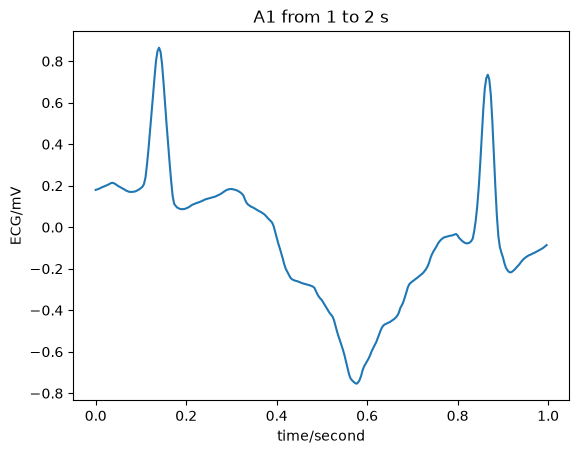

In [69]:
# Returns the original record and the time segment of interest
def segment_signal(signal_number, start_time, end_time):
    record = wfdb.rdheader(f'physionet2017/training2017/A{signal_number:05d}') # Read the record header
    segment = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}', sampfrom=int(start_time * record.fs), sampto=int(end_time * record.fs)) # Read the record segment
    return record, segment

# Plots a segment of interest
def plot_segment(signal_number, start_time, end_time, annotations = None): 
    record = wfdb.rdheader(f'physionet2017/training2017/A{signal_number:05d}')
    segment = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}', sampfrom = int(start_time * record.fs), sampto = int(end_time * record.fs))
    wfdb.plot_wfdb(segment, title = f'A{signal_number} from {start_time} to {end_time} s', annotation = annotations)

plot_segment(1, start_time=1, end_time=2)

### RR Interval Series

Learning initial signal parameters...
Found 8 beats during learning. Initializing using learned parameters
Running QRS detection...
QRS detection complete.


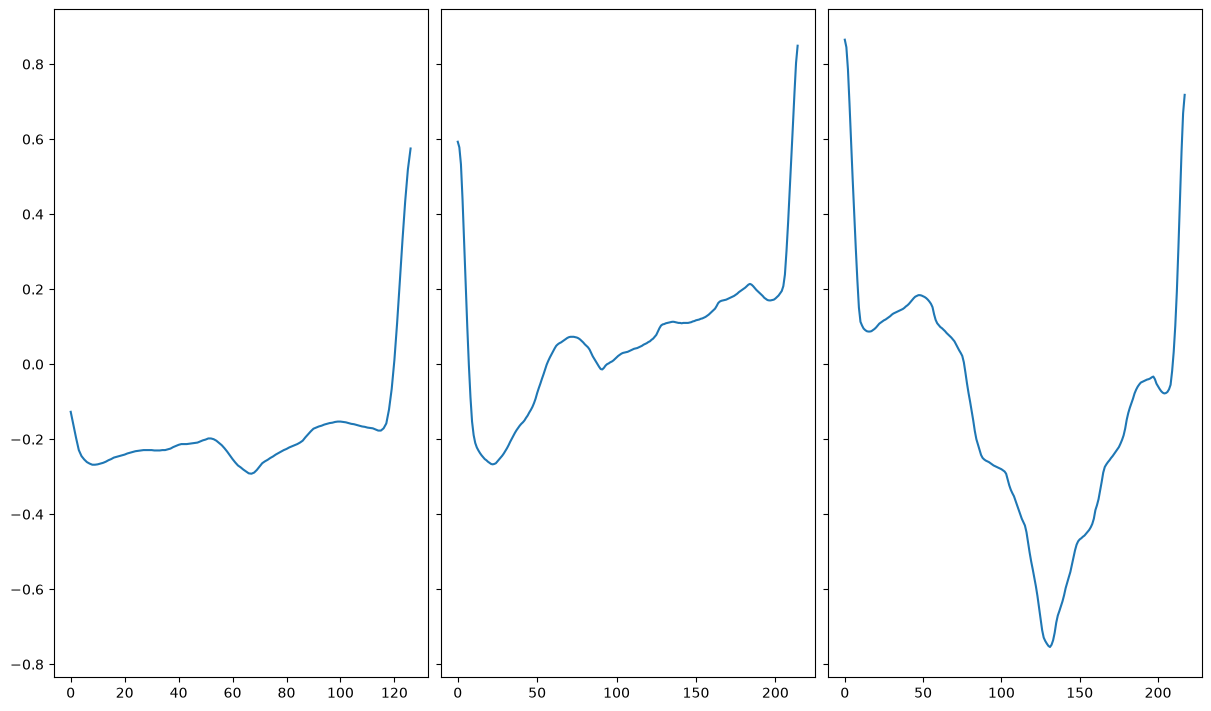

Learning initial signal parameters...
Found 8 beats during learning. Initializing using learned parameters
Running QRS detection...
QRS detection complete.


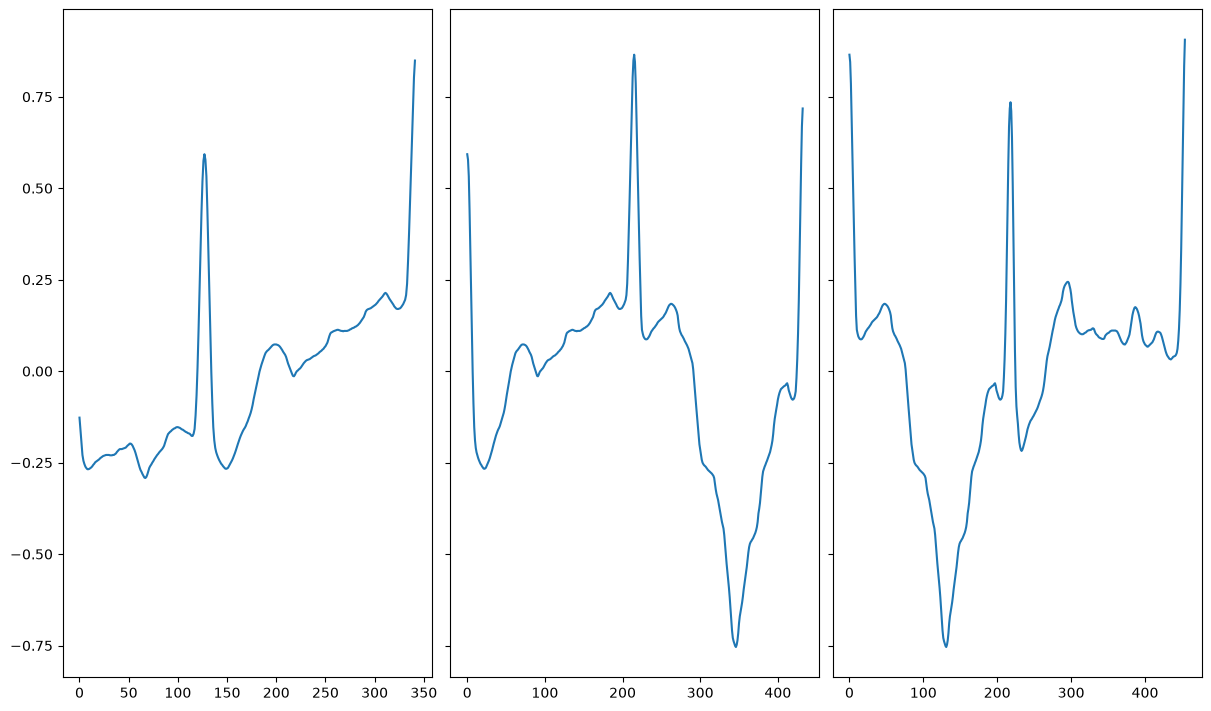

In [113]:
# Plots the locations of the beats detected by the wfdb's own algorithm over a segmented portion of the record.
# Returns the physical signal of the record and the annotations of the beat indices. 
def qrs_locations(signal_number, start_t, stop_t):
    record = wfdb.rdheader(f'physionet2017/training2017/A{signal_number:05d}')
    segment = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}', sampfrom = int(start_t * record.fs), sampto = int(stop_t * record.fs))
    xqrs = processing.XQRS(sig=segment.p_signal[:,0], fs=record.fs)
    xqrs.detect(verbose = True)
    # wfdb.plot_items(signal = segment.p_signal, ann_samp = [xqrs.qrs_inds], fs = record.fs)
    return segment.p_signal, xqrs.qrs_inds #nparrays

# Returns the segments between peaks as arrays in a list
def peak_to_peak(signal_number): 
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}')
    record_p_signal, peaks = qrs_locations(signal_number, 0, record.sig_len / record.fs)
    seg_start = 0
    segments = []
    for peak in peaks:
        seg = record_p_signal[seg_start: peak]
        segments.append(seg)
        seg_start = peak
    return segments

segments = peak_to_peak(1)
fig, axes = plt.subplots(1, 3, figsize = (12, 7), sharey = True, constrained_layout = True)
axes[0].plot(segments[0])
axes[1].plot(segments[1])
axes[2].plot(segments[2])
plt.show()

# Returns the segment around a certain peak (between a peak and the peak after the next peak)
def peak_2_peak(signal_number):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}')
    record_p_signal, peaks = qrs_locations(signal_number, 0, record.sig_len / record.fs)
    seg_start = 0
    segments = []
    for p in range(len(peaks)):
        if p < len(peaks) - 1:
            seg = record_p_signal[seg_start: peaks[p + 1]]
        elif p == len(peaks):
            seg = record_p_signal[seg_start: record_p_signal[-1]]
        seg_start = peaks[p]
        segments.append(seg)
    return segments

segments = peak_2_peak(1)
fig, axes = plt.subplots(1, 3, figsize = (12, 7), sharey = True, constrained_layout = True)
axes[0].plot(segments[0])
axes[1].plot(segments[1])
axes[2].plot(segments[2])
plt.show()


## Data Processing and Cleaning

In [98]:
from scipy.signal import butter, sosfiltfilt

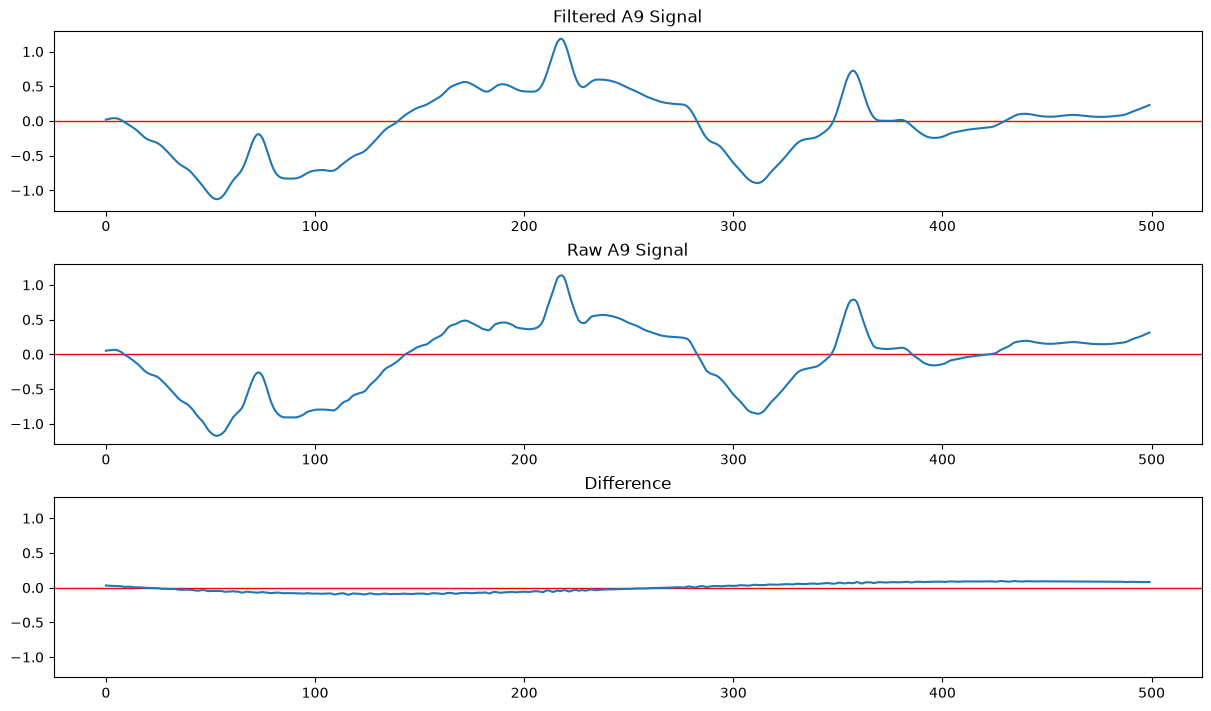

In [128]:
# Bandpass the signal, keeping only the frequencies between low_f and high_f
def bandpass(signal_number, low_f = 0.5, high_f = 40, order = 4):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}')
    signal = record.p_signal[:, 0]
    fs = record.fs
    sos = butter(order, [low_f, high_f], btype = 'bandpass', fs = fs, output = 'sos')
    return sosfiltfilt(sos, signal)

clean = bandpass(9, high_f = 40)

record = wfdb.rdrecord(f'physionet2017/training2017/A{9:05d}')
signal = record.p_signal[:, 0]

fig, axes = plt.subplots(3, 1, figsize = (12, 7), sharey = True, constrained_layout = True)

for ax in axes: 
    ax.axhline(0, color = 'red', linewidth = 1)

axes[0].plot(clean[:500])
axes[0].set_title('Filtered A9 Signal')
axes[1].plot(signal[:500])
axes[1].set_title('Raw A9 Signal')
axes[2].plot(signal[:500] - clean[:500])
axes[2].set_title('Difference')
plt.show()

## Resampling

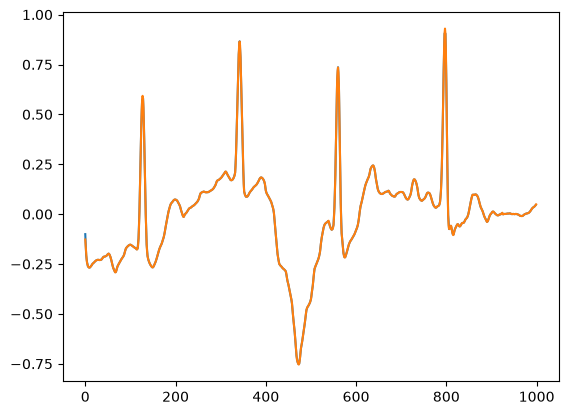

In [ ]:
from scipy.signal import resample_poly
from fractions import Fraction

# Returns the signal resampled at fs_new. 
# For the below plot, the signals are on different x axes as the resampled signal has fewer points. 
def resample(signal_number, fs_new):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}')
    signal = record.p_signal[:, 0]
    fs = record.fs
    ratio = (Fraction(fs_new)/ Fraction(fs)).limit_denominator(1000)
    return resample_poly(signal, ratio.numerator, ratio.denominator)

fs_new = 150
record = wfdb.rdrecord(f'physionet2017/training2017/A{1:05d}')
signal_og = record.p_signal[:, 0]
signal_150 = resample(1, fs_new)
axis = np.arange(len(signal_150)) * record.fs / fs_new
plt.plot(axis[:500], signal_150[:500])
plt.plot(np.arange(len(signal_og))[:1000], signal_og[:1000])

## To Do - NO CLAUDE

#### **Frequency Domain Analysis**
Look into how to extract the frequency spectrum from the training samples. 